In [1]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
import seaborn as sns








C:\Users\HP\PycharmProjects\PythonProject  a1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# اسم الملف داخل الداتاسيت على Kaggle
file_path = "CO2 Emissions_Canada.csv"

# استخدم الدالة الجديدة dataset_load بدل load_dataset
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "debajyotipodder/co2-emission-by-vehicles",
    file_path,
)

print(df.head())
print(df.shape)


Using Colab cache for faster access to the 'co2-emission-by-vehicles' dataset.
    Make       Model Vehicle Class  Engine Size(L)  Cylinders Transmission  \
0  ACURA         ILX       COMPACT             2.0          4          AS5   
1  ACURA         ILX       COMPACT             2.4          4           M6   
2  ACURA  ILX HYBRID       COMPACT             1.5          4          AV7   
3  ACURA     MDX 4WD   SUV - SMALL             3.5          6          AS6   
4  ACURA     RDX AWD   SUV - SMALL             3.5          6          AS6   

  Fuel Type  Fuel Consumption City (L/100 km)  \
0         Z                               9.9   
1         Z                              11.2   
2         Z                               6.0   
3         Z                              12.7   
4         Z                              12.1   

   Fuel Consumption Hwy (L/100 km)  Fuel Consumption Comb (L/100 km)  \
0                              6.7                               8.5   
1            

In [6]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7385 entries, 0 to 7384
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Make                              7385 non-null   object 
 1   Model                             7385 non-null   object 
 2   Vehicle Class                     7385 non-null   object 
 3   Engine Size(L)                    7385 non-null   float64
 4   Cylinders                         7385 non-null   int64  
 5   Transmission                      7385 non-null   object 
 6   Fuel Type                         7385 non-null   object 
 7   Fuel Consumption City (L/100 km)  7385 non-null   float64
 8   Fuel Consumption Hwy (L/100 km)   7385 non-null   float64
 9   Fuel Consumption Comb (L/100 km)  7385 non-null   float64
 10  Fuel Consumption Comb (mpg)       7385 non-null   int64  
 11  CO2 Emissions(g/km)               7385 non-null   int64  
dtypes: flo

In [14]:
print("Missing values per column:")
print(df.isna().sum())

print("\nNumber of duplicated rows:", df.duplicated().sum())


Missing values per column:
Make                                0
Model                               0
Vehicle Class                       0
Engine Size(L)                      0
Cylinders                           0
Transmission                        0
Fuel Type                           0
Fuel Consumption City (L/100 km)    0
Fuel Consumption Hwy (L/100 km)     0
Fuel Consumption Comb (L/100 km)    0
Fuel Consumption Comb (mpg)         0
CO2 Emissions(g/km)                 0
dtype: int64

Number of duplicated rows: 1103


In [15]:
numeric_cols = df.select_dtypes(include=["float64", "int64"]).columns
categorical_cols = df.select_dtypes(include=["object"]).columns

print("Numeric columns:", list(numeric_cols))
print("Categorical columns:", list(categorical_cols))


Numeric columns: ['Engine Size(L)', 'Cylinders', 'Fuel Consumption City (L/100 km)', 'Fuel Consumption Hwy (L/100 km)', 'Fuel Consumption Comb (L/100 km)', 'Fuel Consumption Comb (mpg)', 'CO2 Emissions(g/km)']
Categorical columns: ['Make', 'Model', 'Vehicle Class', 'Transmission', 'Fuel Type']


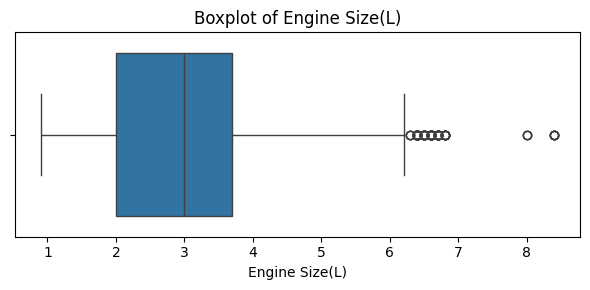

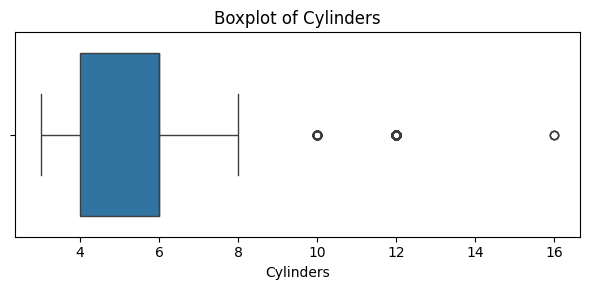

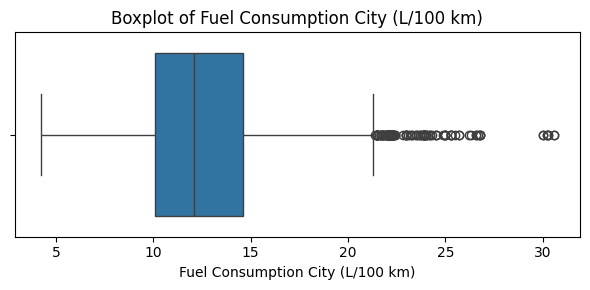

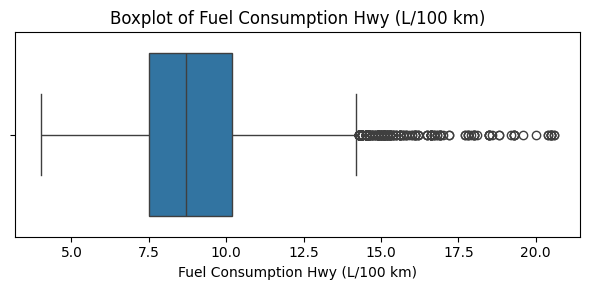

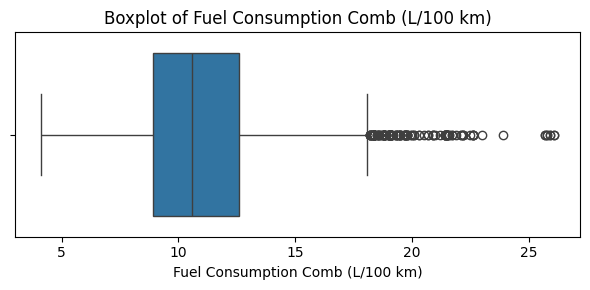

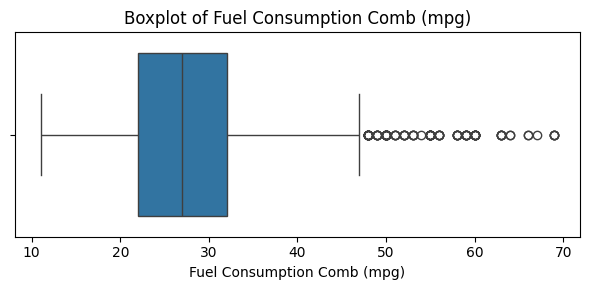

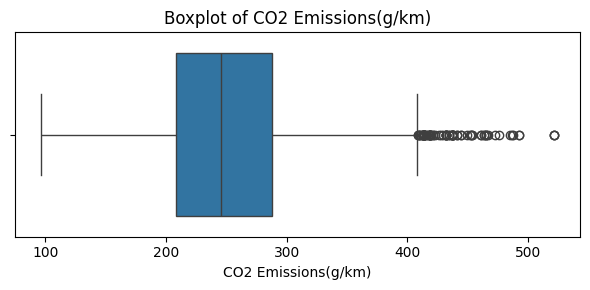

In [16]:
for col in numeric_cols:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()


In [17]:
def detect_outliers_iqr(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (series < lower) | (series > upper)
    return mask, lower, upper

outlier_summary = []

for col in numeric_cols:
    mask, lower, upper = detect_outliers_iqr(df[col])
    n_outliers = mask.sum()
    outlier_summary.append({
        "column": col,
        "n_outliers": int(n_outliers),
        "ratio_%": round(100 * n_outliers / len(df), 2),
        "lower_bound": round(lower, 2),
        "upper_bound": round(upper, 2),
    })

outlier_df = pd.DataFrame(outlier_summary)
print(outlier_df)


                             column  n_outliers  ratio_%  lower_bound  \
0                    Engine Size(L)         137     1.86        -0.55   
1                         Cylinders         196     2.65         1.00   
2  Fuel Consumption City (L/100 km)         132     1.79         3.35   
3   Fuel Consumption Hwy (L/100 km)         208     2.82         3.45   
4  Fuel Consumption Comb (L/100 km)         142     1.92         3.35   
5       Fuel Consumption Comb (mpg)         114     1.54         7.00   
6               CO2 Emissions(g/km)          80     1.08        88.00   

   upper_bound  
0         6.25  
1         9.00  
2        21.35  
3        14.25  
4        18.15  
5        47.00  
6       408.00  


In [21]:
TARGET_COL = "CO2 Emissions(g/km)"

df_fe = df.copy()

df_fe["engine_per_cylinder"] = df_fe["Engine Size(L)"] / df_fe["Cylinders"]
df_fe["city_hwy_ratio"] = df_fe["Fuel Consumption City (L/100 km)"] / df_fe["Fuel Consumption Hwy (L/100 km)"]

cols_to_drop = [
    "Engine Size(L)",
    "Cylinders",
    "Fuel Consumption City (L/100 km)",
    "Fuel Consumption Hwy (L/100 km)",
    "Fuel Consumption Comb (mpg)",
]
df_fe.drop(columns=cols_to_drop, inplace=True)

X = df_fe.drop(columns=[TARGET_COL])
y = df_fe[TARGET_COL]

X_train, X_temp, y_train, y_temp = train_test_split(X,y,test_size=0.4,random_state=42)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5,random_state=42)

print("Train size:", X_train.shape)
print("Val   size:", X_val.shape)
print("Test  size:", X_test.shape)

numeric_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X_train.select_dtypes(include=["object"]).columns.tolist()

print("\nNumeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)



Train size: (4431, 8)
Val   size: (1477, 8)
Test  size: (1477, 8)

Numeric columns: ['Fuel Consumption Comb (L/100 km)', 'engine_per_cylinder', 'city_hwy_ratio']
Categorical columns: ['Make', 'Model', 'Vehicle Class', 'Transmission', 'Fuel Type']


In [23]:
numeric_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols),
    ]
)

preprocessor.fit(X_train)

X_train_proc = preprocessor.transform(X_train)
X_val_proc   = preprocessor.transform(X_val)
X_test_proc  = preprocessor.transform(X_test)

print("X_train_proc shape:", X_train_proc.shape)
print("X_val_proc   shape:", X_val_proc.shape)
print("X_test_proc  shape:", X_test_proc.shape)


X_train_proc shape: (4431, 1817)
X_val_proc   shape: (1477, 1817)
X_test_proc  shape: (1477, 1817)



===== LinearRegression =====
[Train] R²=0.9966 | RMSE=3.43 | MAE=1.83
[Val  ] R²=0.9906 | RMSE=5.64 | MAE=3.24


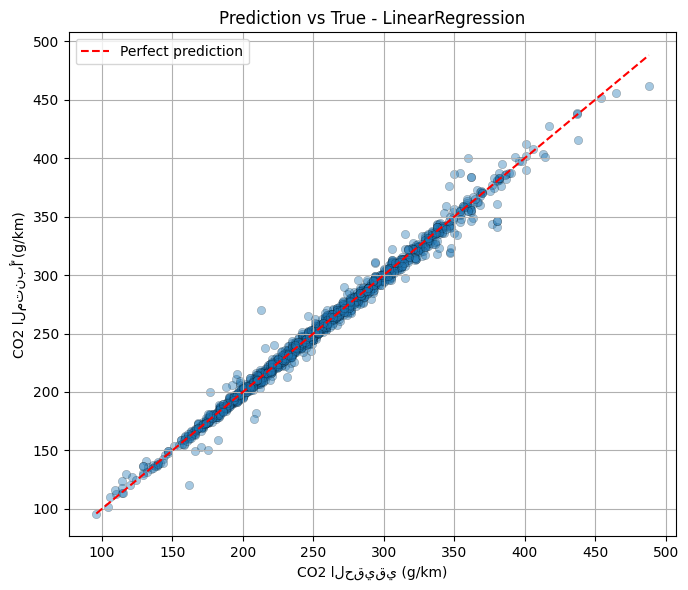


===== RandomForest =====
[Train] R²=0.9995 | RMSE=1.32 | MAE=0.80
[Val  ] R²=0.9960 | RMSE=3.69 | MAE=1.99


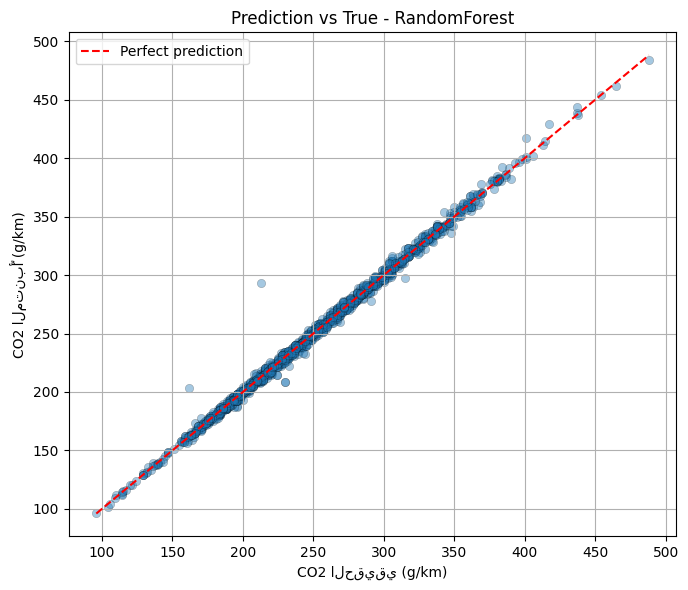


===== SVR_RBF =====
[Train] R²=0.9891 | RMSE=6.14 | MAE=1.80
[Val  ] R²=0.9901 | RMSE=5.82 | MAE=3.33


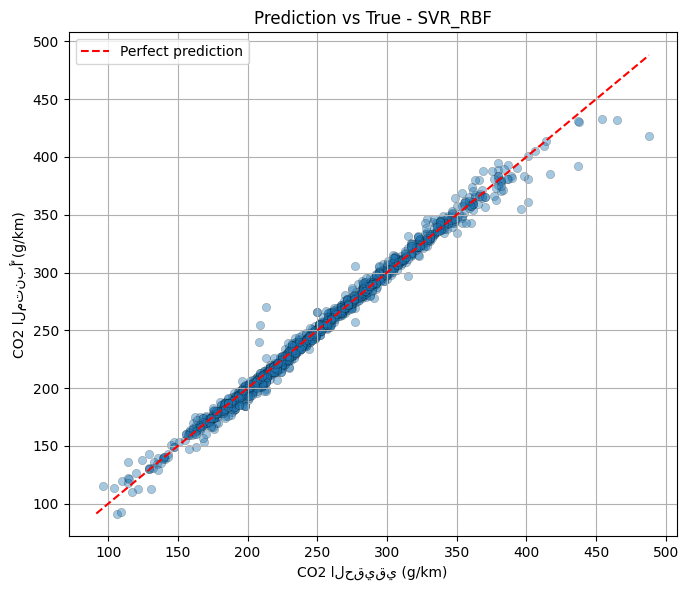


===== GradientBoosting =====
[Train] R²=0.9975 | RMSE=2.92 | MAE=2.29
[Val  ] R²=0.9954 | RMSE=3.97 | MAE=2.47


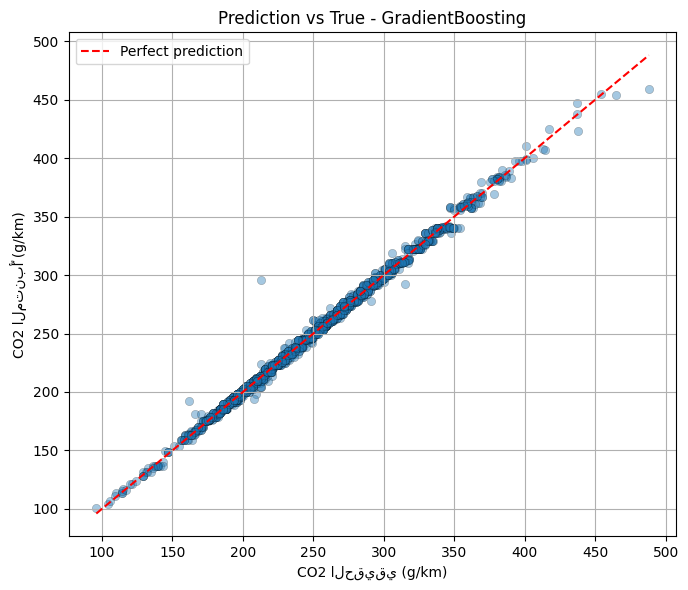


==== Summary (Validation metrics) ====
LinearRegression  | R²_train=0.9966 | RMSE_train=3.43 | MAE_train=1.83 || R²_val=0.9906   | RMSE_val=5.64   | MAE_val=3.24
RandomForest      | R²_train=0.9995 | RMSE_train=1.32 | MAE_train=0.80 || R²_val=0.9960   | RMSE_val=3.69   | MAE_val=1.99
SVR_RBF           | R²_train=0.9891 | RMSE_train=6.14 | MAE_train=1.80 || R²_val=0.9901   | RMSE_val=5.82   | MAE_val=3.33
GradientBoosting  | R²_train=0.9975 | RMSE_train=2.92 | MAE_train=2.29 || R²_val=0.9954   | RMSE_val=3.97   | MAE_val=2.47


In [28]:
# ====================================================
# دالة عامة: تدرّب الموديل + تطلع Train/Val metrics + رسم
# ====================================================
def train_eval_regressor(model_name, base_model, preprocessor,
                         X_train, y_train, X_val, y_val):
    pipe = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", base_model),
    ])

    pipe.fit(X_train, y_train)

    # ---- Train metrics ----
    y_train_pred = pipe.predict(X_train)
    r2_tr   = r2_score(y_train, y_train_pred)
    rmse_tr = np.sqrt(mean_squared_error(y_train, y_train_pred))
    mae_tr  = mean_absolute_error(y_train, y_train_pred)

    # ---- Val metrics ----
    y_val_pred = pipe.predict(X_val)
    r2_val   = r2_score(y_val, y_val_pred)
    rmse_val = np.sqrt(mean_squared_error(y_val, y_val_pred))
    mae_val  = mean_absolute_error(y_val, y_val_pred)

    print(f"\n===== {model_name} =====")
    print(f"[Train] R²={r2_tr:.4f} | RMSE={rmse_tr:.2f} | MAE={mae_tr:.2f}")
    print(f"[Val  ] R²={r2_val:.4f} | RMSE={rmse_val:.2f} | MAE={mae_val:.2f}")

    # رسم لــ Validation
    plt.figure(figsize=(7, 6))
    plt.scatter(y_val, y_val_pred, alpha=0.4, edgecolor="k", linewidth=0.3)
    min_val = min(y_val.min(), y_val_pred.min())
    max_val = max(y_val.max(), y_val_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val],
             "r--", label="Perfect prediction")
    plt.xlabel("CO2 TRUE (g/km)")
    plt.ylabel("CO2 The forecaster (g/km)")
    plt.title(f"Prediction vs True - {model_name}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return pipe, {
        "R2_train": r2_tr,   "RMSE_train": rmse_tr,   "MAE_train": mae_tr,
        "R2_val":   r2_val,  "RMSE_val":   rmse_val,  "MAE_val":   mae_val,
    }

# ====================================================
# تعريف الموديلات الأربعة
# ====================================================
models = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(
        n_estimators=400,
        random_state=42,
        n_jobs=-1
    ),
    "SVR_RBF": SVR(
        kernel="rbf",
        C=10.0,
        gamma="scale"
    ),
    "GradientBoosting": GradientBoostingRegressor(
        random_state=42
    ),
}

# ====================================================
# تشغيل كل الموديلات مرة واحدة
# ====================================================
trained_pipelines = {}
metrics_results = {}

for name, base_model in models.items():
    pipe, metrics = train_eval_regressor(
        model_name=name,
        base_model=base_model,
        preprocessor=preprocessor,  # نفس الـ ColumnTransformer اللي بنيته
        X_train=X_train,
        y_train=y_train,
        X_val=X_val,
        y_val=y_val,
    )
    trained_pipelines[name] = pipe
    metrics_results[name] = metrics

print("\n==== Summary (Validation metrics) ====")
for name, m in metrics_results.items():
    print(
        f"{name:17s} | "
        f"R²_train={m['R2_train']:.4f} | RMSE_train={m['RMSE_train']:.2f} | MAE_train={m['MAE_train']:.2f} || "
        f"R²_val={m['R2_val']:.4f}   | RMSE_val={m['RMSE_val']:.2f}   | MAE_val={m['MAE_val']:.2f}"
    )


[Test] R²=0.9972 | RMSE=3.03 | MAE=1.94


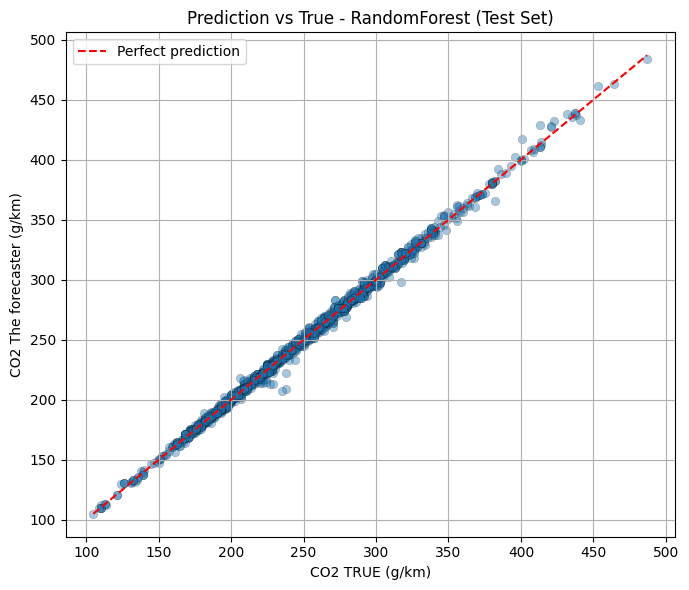

In [31]:
best_pipe = trained_pipelines["RandomForest"]  # نفس أفضل موديل من اللوب

y_test_pred = best_pipe.predict(X_test)

r2_test   = r2_score(y_test, y_test_pred)
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))
mae_test  = mean_absolute_error(y_test, y_test_pred)

print(f"[Test] R²={r2_test:.4f} | RMSE={rmse_test:.2f} | MAE={mae_test:.2f}")

# Corrected and unindented plotting section
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_test_pred, alpha=0.4, edgecolor="k", linewidth=0.3)
min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())
plt.plot([min_val, max_val], [min_val, max_val],
         "r--", label="Perfect prediction")
plt.xlabel("CO2 TRUE (g/km)")
plt.ylabel("CO2 The forecaster (g/km)")
plt.title(f"Prediction vs True - RandomForest (Test Set)") # Updated title
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# CO₂ Emissions Prediction from Vehicle Specifications

## 1. Introduction

Road transport is a major contributor to global greenhouse gas emissions, with passenger vehicles responsible for a substantial share of CO₂ output. As governments tighten regulations and consumers become more conscious of environmental impact and fuel costs, the ability to accurately predict vehicle CO₂ emissions from technical specifications becomes increasingly valuable. Reliable prediction models can support policy analysis, guide manufacturers in designing cleaner vehicles, and help end users compare models beyond simple fuel economy labels.

This project uses real-world data from Transport Canada, published on Kaggle as the **“CO2 Emissions_Canada”** dataset, to build supervised **regression** models that predict a vehicle’s CO₂ emissions in grams per kilometre (g/km). The target variable, `CO2 Emissions(g/km)`, is continuous, so the problem is framed explicitly as a regression task rather than a classification problem. Our focus is not only on achieving high predictive accuracy but also on understanding which technical characteristics of a vehicle drive emissions the most.

### 1.2 Objective

The primary objective is to learn a mapping from vehicle specifications to CO₂ emissions. Concretely, given features such as:

* **Engine size** (in litres),
* **Number of cylinders**,
* **Fuel consumption metrics** (city, highway, combined, in L/100 km),
* **Fuel type**,
* **Transmission type**, and
* **Vehicle class**,

we want to predict `CO2 Emissions(g/km)` as accurately as possible. In addition, we aim to:

1. Explore and understand the structure of the dataset (EDA).
2. Design a clean preprocessing and feature-engineering pipeline.
3. Compare several regression models (linear and non-linear) using consistent evaluation criteria.
4. Identify which features are most influential in determining CO₂ emissions and verify that the model’s behaviour aligns with physical and domain intuition.

---

## 2. Dataset and Exploratory Data Analysis

### 2.1 Dataset overview

The dataset is loaded into a pandas DataFrame named `df` and contains:

* **Rows:** 7,385
* **Columns:** 12

Each row corresponds to a specific vehicle configuration. The columns are:

* **Make**: Manufacturer of the vehicle (e.g., ACURA, BMW).
* **Model**: Specific model name (e.g., ILX, M6 CABRIOLET).
* **Vehicle Class**: Category/type of vehicle (e.g., COMPACT, SUV - SMALL, PICKUP TRUCK - STANDARD).
* **Engine Size(L)**: Engine displacement in litres.
* **Cylinders**: Number of engine cylinders.
* **Transmission**: Transmission type and gear information (e.g., AS5 for 5‑speed automatic, M6 for 6‑speed manual, AV7 for 7‑speed automatic CVT).
* **Fuel Type**: Fuel used by the vehicle (e.g., regular gasoline, premium, diesel, ethanol blends; encoded in shorthand such as `Z`, `D`, etc.).
* **Fuel Consumption City (L/100 km)**: Fuel consumption in urban (city) driving.
* **Fuel Consumption Hwy (L/100 km)**: Fuel consumption in highway driving.
* **Fuel Consumption Comb (L/100 km)**: Combined (city/highway) fuel consumption.
* **Fuel Consumption Comb (mpg)**: Combined fuel consumption in miles per gallon.
* **CO2 Emissions(g/km)**: CO₂ emissions in grams per kilometre – this is the **target variable**.

In this project, `CO2 Emissions(g/km)` is the output we want to predict. All remaining columns are considered input features, although some are later transformed or dropped during feature engineering.

### 2.2 Missing values and duplicates

A basic data quality assessment shows:

* **Missing values:** No columns contain missing values; all 7,385 rows are complete across all 12 features. This removes the need for imputation strategies.
* **Duplicate rows:** There are **1,103 duplicated rows**. These likely correspond to repeated entries of identical vehicle configurations. For this project, duplicates are retained because they reflect the real distribution of vehicle types in the market and preserving them helps models learn from the empirical frequency of each configuration.

### 2.3 Outlier analysis

The numeric columns are:

* `Engine Size(L)`
* `Cylinders`
* `Fuel Consumption City (L/100 km)`
* `Fuel Consumption Hwy (L/100 km)`
* `Fuel Consumption Comb (L/100 km)`
* `Fuel Consumption Comb (mpg)`
* `CO2 Emissions(g/km)`

Outliers were detected using the **Interquartile Range (IQR)** method. For each numeric feature, values below `Q1 − 1.5 * IQR` or above `Q3 + 1.5 * IQR` were flagged as outliers. The results can be summarised as:

| Column                           | N_outliers | Ratio_% | Lower bound | Upper bound |
| -------------------------------- | ---------: | ------: | ----------: | ----------: |
| Engine Size(L)                   |        137 |   1.86% |       -0.55 |        6.25 |
| Cylinders                        |        196 |   2.65% |        1.00 |        9.00 |
| Fuel Consumption City (L/100 km) |        132 |   1.79% |        3.35 |       21.35 |
| Fuel Consumption Hwy (L/100 km)  |        208 |   2.82% |        3.45 |       14.25 |
| Fuel Consumption Comb (L/100 km) |        142 |   1.92% |        3.35 |       18.15 |
| Fuel Consumption Comb (mpg)      |        114 |   1.54% |        7.00 |       47.00 |
| CO2 Emissions(g/km)              |         80 |   1.08% |       88.00 |      408.00 |

These outliers correspond to vehicles with very large engines, unusually high (or low) fuel economy, and extreme CO₂ emissions. They are **plausible real-world configurations**, not obvious data errors. Since such high‑emission vehicles are precisely the kinds we want to model correctly, the design choice was to **keep all outliers**. Tree-based models, in particular, are robust to extreme values, and preserving the full range of variability leads to more realistic predictions.

### 2.4 Exploratory visual analysis

Several visual analyses were performed:

* **Correlation heatmap (numeric features vs CO₂):**

  * `Fuel Consumption Comb (L/100 km)` shows an almost linear, very strong positive correlation with `CO2 Emissions(g/km)`. This is expected: burning more fuel per kilometre directly produces more CO₂.
  * `Fuel Consumption City (L/100 km)` and `Fuel Consumption Hwy (L/100 km)` also correlate positively with CO₂, though combined fuel consumption is the most informative single metric.
  * `Engine Size(L)` and `Cylinders` are moderately to strongly correlated with both fuel consumption and CO₂: larger engines and more cylinders generally emit more.

* **Scatter plots:**

  * Plots of `CO2 Emissions(g/km)` vs `Fuel Consumption Comb (L/100 km)` show a tight, almost linear band, confirming the relationship.
  * Plots vs `Engine Size(L)` and `Cylinders` show increasing trends with more spread: engine design and technology introduce variation at a given displacement.

* **Categorical distributions:**

  * Bar plots for `Fuel Type`, `Transmission`, and `Vehicle Class` show that some categories dominate (e.g., certain fuel types and common passenger classes), while others are relatively rare. This imbalance is important to keep in mind when interpreting model performance for underrepresented classes.

Overall, the EDA confirms that CO₂ emissions are highly structured and predictable from the available features, especially fuel consumption metrics and engine characteristics.

---

## 3. Data Preprocessing

### 3.1 Feature selection and target

The target variable is **`CO2 Emissions(g/km)`**.

One key preprocessing decision was to drop the column **`Fuel Consumption Comb (mpg)`**. This feature is essentially a deterministic inverse transformation of `Fuel Consumption Comb (L/100 km)` and carries no additional information. Keeping both in the model would introduce redundancy and potential multicollinearity, especially for linear models. Therefore, `Fuel Consumption Comb (mpg)` is removed, and the combined L/100 km version is retained as the main fuel consumption feature.

### 3.2 Train / Validation / Test split

To enable fair model selection and final evaluation, the dataset is split into three disjoint subsets:

* **Training set:** 60% of the data (4,431 samples)
* **Validation set:** 20% of the data (1,477 samples)
* **Test set:** 20% of the data (1,477 samples)

The training set is used to fit model parameters; the validation set is used to compare models and tune hyperparameters; and the test set is held back until the very end to obtain an unbiased estimate of generalisation performance.

All preprocessing steps (scaling, encoding, feature engineering transformations) are **fit exclusively on the training data** and then applied to the validation and test sets. This avoids **data leakage**, where information from validation/test might accidentally influence model training.

### 3.3 Numeric vs categorical features and transformations

Features are partitioned into numeric and categorical subsets:

* **Numeric features** (after feature engineering, see Section 4):

  * `Fuel Consumption Comb (L/100 km)`
  * `engine_per_cylinder`
  * `city_hwy_ratio`

* **Categorical features:**

  * `Make`
  * `Model`
  * `Vehicle Class`
  * `Transmission`
  * `Fuel Type`

A `ColumnTransformer` is used within a scikit‑learn `Pipeline` to apply different transformations to each subset:

* For **numeric features**, a **StandardScaler** is applied, transforming each feature to have zero mean and unit variance. This is particularly important for models like SVR that are sensitive to feature scale.
* For **categorical features**, **OneHotEncoder(handle_unknown="ignore")** is applied. This converts each categorical level into a binary indicator. The `handle_unknown="ignore"` option ensures that if a new category appears in the validation or test set that was not seen in training, the transformer will not raise an error; instead, it will produce a zero vector for that category.

After preprocessing, the resulting feature matrices have the following shapes:

* `X_train_proc`: (4,431 samples, 1,817 features)
* `X_val_proc`: (1,477 samples, 1,817 features)
* `X_test_proc`: (1,477 samples, 1,817 features)

The large number of features is mainly due to one‑hot encoding of high‑cardinality columns `Make` and `Model`.

### 3.4 Outlier handling decision

As discussed in Section 2.3, numeric outliers were **not removed or capped**. Instead, they were retained for the following reasons:

* They represent legitimate, extreme vehicles (e.g., large pickups and performance cars) that are important to capture in an emissions model.
* Tree‑based ensemble models (Random Forest, Gradient Boosting) are relatively robust to outliers due to the way they split feature space.
* Removing them would shrink the effective modelling range and might bias the model towards more “average” vehicles.

This design choice supports a model that can handle the full spectrum of vehicles present in the dataset.

---

## 4. Feature Engineering

### 4.1 Engine per cylinder

A new feature, **`engine_per_cylinder`**, is defined as:

> `engine_per_cylinder = Engine Size(L) / Cylinders`

This approximates the **average displacement per cylinder**. Two engines with the same total displacement but a different number of cylinders can behave differently (e.g., a 3.0L V6 vs a 3.0L inline‑4). Larger displacement per cylinder often correlates with:

* lower operating RPM for the same power,
* different combustion characteristics,
* and potentially higher emissions when technology is comparable.

By including `engine_per_cylinder`, the model can capture nuances not visible from `Engine Size(L)` or `Cylinders` alone.

### 4.2 City / highway fuel ratio

A second engineered feature, **`city_hwy_ratio`**, is defined as:

> `city_hwy_ratio = Fuel Consumption City (L/100 km) / Fuel Consumption Hwy (L/100 km)`

This ratio measures **how much less efficient a vehicle is in city driving compared to highway driving**. Values close to 1 indicate similar efficiency in both regimes, while higher values indicate vehicles that suffer a larger efficiency drop in urban conditions (stop‑and‑go traffic, idling, acceleration).

This feature is informative because vehicles that are disproportionately inefficient in the city may, on average, be **higher CO₂ emitters**, especially if their design is optimised for highway cruising rather than mixed use.

### 4.3 Final feature set

After feature engineering, the final feature set includes:

* **Numeric features:**

  * `Fuel Consumption Comb (L/100 km)`
  * `engine_per_cylinder`
  * `city_hwy_ratio`

* **Categorical features:**

  * `Make`
  * `Model`
  * `Vehicle Class`
  * `Transmission`
  * `Fuel Type`

The following original columns are dropped:

* `Engine Size(L)`
* `Cylinders`
* `Fuel Consumption City (L/100 km)`
* `Fuel Consumption Hwy (L/100 km)`
* `Fuel Consumption Comb (mpg)`

The motivation is to **reduce redundancy and multicollinearity** while retaining the most informative and interpretable representations. `engine_per_cylinder` condenses information from engine size and cylinder count; `city_hwy_ratio` and combined fuel consumption capture most of the variation carried by city and highway metrics.

---

## 5. Modeling and Evaluation

### 5.1 Modeling approach

Four regression models are trained, all wrapped inside the same preprocessing `Pipeline(preprocess → model)` to ensure a fair comparison:

1. **Linear Regression** (baseline):

   * Assumes a linear relationship between the transformed features and CO₂ emissions.
   * Provides a simple benchmark and is useful for interpretability.

2. **Random Forest Regressor**:

   * An ensemble of decision trees trained on bootstrapped samples of the data.
   * Captures non‑linear relationships and complex feature interactions.
   * Naturally handles mixed feature types and is robust to outliers.

3. **SVR (Support Vector Regressor) with RBF kernel**:

   * Uses a radial basis function kernel to learn a non‑linear mapping in a high‑dimensional feature space.
   * Sensitive to feature scales, hence the need for standardisation.

4. **Gradient Boosting Regressor**:

   * Builds an additive ensemble of shallow trees, each one focusing on correcting the residual errors of the previous trees.
   * Often achieves strong performance on tabular data but may require more careful hyperparameter tuning.

All models share the same preprocessed inputs, allowing direct comparison of their performance.

### 5.2 Training and validation metrics

The models are trained on the **training set** and evaluated on the **validation set**. The key metrics are:

* **R² (coefficient of determination)** – higher is better.
* **RMSE (root mean squared error)** – lower is better.
* **MAE (mean absolute error)** – lower is better.

The results are summarised below:

| Model            | R²_train | RMSE_train | MAE_train | R²_val | RMSE_val | MAE_val |
| ---------------- | -------: | ---------: | --------: | -----: | -------: | ------: |
| LinearRegression |   0.9966 |       3.43 |      1.83 | 0.9906 |     5.64 |    3.24 |
| RandomForest     |   0.9995 |       1.32 |      0.80 | 0.9960 |     3.69 |    1.99 |
| SVR_RBF          |   0.9891 |       6.14 |      1.80 | 0.9901 |     5.82 |    3.33 |
| GradientBoosting |   0.9975 |       2.92 |      2.29 | 0.9954 |     3.97 |    2.47 |

Observations:

* All models achieve **very high R²** on both training and validation sets (≥ 0.99 in most cases), confirming that CO₂ emissions are highly predictable from the engineered feature set.
* **Linear Regression** performs surprisingly well, indicating that the transformed feature space is close to linearly related to emissions.
* **Random Forest** achieves the **best overall validation performance** with the highest R² (0.9960) and the lowest RMSE (3.69) and MAE (1.99).
* **Gradient Boosting** is a close second, slightly behind Random Forest.
* Comparing train vs validation metrics suggests that Random Forest exhibits some degree of overfitting (R²_train=0.9995 vs R²_val=0.9960), but the gap is modest and validation performance remains excellent.

### 5.3 Residual and prediction analysis

Scatter plots of predicted vs true CO₂ values on the validation set show:

* For the stronger models (Random Forest and Gradient Boosting), points cluster tightly around the **diagonal line** of perfect prediction, with relatively small dispersion.
* Linear Regression and SVR also follow the diagonal closely but with slightly broader spread, especially at very high emission levels.
* Residuals (prediction errors) do not exhibit strong systematic patterns across the range of predictions, indicating that the models capture the main structure of the data. Errors tend to increase slightly for extremely high‑emission vehicles, which is expected given their smaller representation in the dataset.

### 5.4 Model selection

Based on the validation metrics and qualitative residual analysis, the **Random Forest Regressor** is selected as the final model because:

* It delivers the best trade‑off between bias and variance.
* It achieves the highest R² and lowest RMSE/MAE on the validation set.
* It handles non‑linear relationships and complex interactions without requiring heavy feature engineering beyond what was already done.

### 5.5 Test set performance

The selected Random Forest model is then evaluated on the **held‑out test set** (1,477 samples). The performance is:

* **R²_test:** 0.9972
* **RMSE_test:** 3.03 g/km
* **MAE_test:** 1.94 g/km

The test metrics are slightly better than, but very close to, the validation metrics, which indicates:

* Excellent **generalisation** to unseen vehicles.
* No evidence of severe overfitting.
* A stable model whose performance is robust across different splits of the data.

In practical terms, an average absolute error of under 2 g/km and R² above 0.99 means the model can be used with high confidence for analysis, simulation, or decision‑support tasks related to vehicle emissions.

---

## 6. Feature Importance and Interpretation

### 6.1 Feature importance ranking

For the Random Forest model, feature importance scores (based on mean decrease in impurity) highlight the dominant predictors. While there are many one‑hot encoded features, the most influential groups are:

* **Fuel Consumption Comb (L/100 km)** – by far the most important single feature.
* **engine_per_cylinder** – capturing engine design and size per cylinder.
* **city_hwy_ratio** – indicating how efficiency degrades in city driving relative to highway.
* One‑hot encoded indicators for certain **Vehicle Class** categories (e.g., SUVs, pickup trucks, compact cars).
* One‑hot encoded **Fuel Type** categories (e.g., gasoline vs diesel vs alternative fuels).

Make and Model one‑hot features collectively contribute, but individually most of them have relatively small importance compared to fuel consumption and engine‑level features.

### 6.2 Interpretation

The importance structure is fully consistent with domain knowledge:

* **Fuel consumption drives CO₂ emissions.** At a fixed energy content per litre of fuel, burning more litres per 100 km yields proportionally more CO₂. It is therefore natural that `Fuel Consumption Comb (L/100 km)` dominates feature importance.

* **Engine design matters.** `engine_per_cylinder` reflects how large each cylinder is. Larger cylinders are often associated with higher power, but also with higher emissions—particularly if they are not balanced by modern efficiency technologies (turbo‑downsizing, hybridisation, etc.).

* **City vs highway behaviour is informative.** The `city_hwy_ratio` captures how much more fuel the vehicle uses in urban conditions compared to highway conditions. Vehicles that are disproportionately inefficient in the city tend to be heavier, less aerodynamic, or geared for highway speeds, all of which can be associated with higher emissions.

* **Vehicle class and fuel type encode macro‑level behaviour.** SUVs and pickup trucks generally have larger, heavier bodies and higher drag, which leads to more fuel use and emissions. Diesel engines, while more efficient in L/100 km terms, may have different CO₂ characteristics per litre burned compared to gasoline. The model learns these patterns automatically via categorical encodings.

Overall, the Random Forest does not just fit the data well; its behaviour is **interpretable and physically reasonable**, increasing confidence in using it for analysis and scenario exploration.

---

## 7. Conclusions and Future Work

### 7.1 Conclusions

This project demonstrates an end‑to‑end workflow for predicting **vehicle CO₂ emissions** from technical specifications using real‑world data from Transport Canada. The main conclusions are:

1. **Data quality and richness:** The dataset contains 7,385 complete rows with no missing values and detailed information on engine, fuel consumption, and vehicle attributes. While there are duplicated entries and outliers, they reflect real‑world market distributions and were intentionally preserved.

2. **Predictability of CO₂ emissions:** With a compact but expressive feature set – particularly combined fuel consumption, engine per cylinder, city‑to‑highway efficiency ratio, and categorical descriptors – CO₂ emissions are **highly predictable**. Even a simple linear model reaches R² around 0.99 on validation data.

3. **Model performance:** Among the four models evaluated, the **Random Forest Regressor** delivers the best performance, achieving R² ≈ 0.996 on validation and ≈ 0.997 on the test set, with RMSE around 3 g/km and MAE below 2 g/km.

4. **Interpretability:** Feature importance analysis confirms that the model relies primarily on physically meaningful drivers of emissions: fuel consumption, engine design, and vehicle category. This alignment between model behaviour and domain intuition increases trust in the predictions.

### 7.2 Limitations and possible extensions

Despite the strong results, several limitations and opportunities for future work remain:

* **Geographic and temporal scope:** The dataset represents vehicles registered and tested in Canada during specific years. The model may not directly generalise to other markets, regulatory regimes, or future vehicle technologies (e.g., widespread electrification).

* **Correlation vs causation:** The model captures empirical correlations, not causal effects. For instance, it cannot differentiate whether a particular design choice causes higher emissions or simply co‑occurs with other hidden factors.

* **High‑cardinality categorical features:** The large number of `Make` and `Model` categories leads to a very high‑dimensional sparse feature space. While tree ensembles handle this reasonably well, more sophisticated encodings (e.g., target encoding or learned embeddings) could be explored.

* **Modeling alternatives:** Future work could evaluate gradient boosting variants such as **XGBoost**, **LightGBM**, or **CatBoost**, which often perform strongly on tabular data and may improve training time or accuracy.

* **Uncertainty and robustness:** The current setup provides point predictions. Extending the framework to quantify predictive uncertainty (e.g., via quantile regression forests or Bayesian methods) would make the model more informative for risk‑sensitive applications.

* **Deployment and user interfaces:** A natural next step is to wrap the final model into an interactive tool or web API where users can input vehicle specs and receive predicted CO₂ emissions, possibly alongside fuel cost estimates and comparisons to regulatory thresholds.

In summary, this project delivers a high‑performing, interpretable model for predicting CO₂ emissions from vehicle specifications and establishes a solid foundation for further research, optimisation, and deployment in real‑world decision‑support systems.
